# Phase 4 (final): Fusion Comparison, Ablations, Controls + End-to-End Checkpoints

Question for this phase: **does real weather context add anything beyond a strong image-only model on GVLiD?**

**Part A/B (fast, cached embeddings)** - frozen ConvNeXt-T / Swin-T / MobileNetV2 embeddings are extracted once; small fusion heads then train in seconds, so every experiment runs over 5 seeds:
- fusion strategies: `image_only`, `concat`, `late`, `gated`, `film`
- weather feature ablation (temperature / humidity / rainfall) and window ablation (1d / 3d / 7d / 14d / multi-scale)
- retrained controls: shuffled weather, zero weather, and a **grid-cell one-hot** (location ID, no weather values)
- paired **group-bootstrap** confidence intervals on test macro-F1

**Part C (end-to-end, with checkpoints)** - the validation-selected backbone + fusion head and the image-only head are trained with image augmentation, saved as self-contained checkpoints (for Phase 5 Grad-CAM), and diagnosed with test-time weather zeroing/shuffling.

Selection rules: backbone and fusion head are chosen on **validation** macro-F1 only. The test split is never used for selection.

Honest limitations (they go in the paper):
- Phase 2 windows are nested aggregates (the 14-day mean contains the 7-day mean), **not** a day-by-day sequence. The `gru` variant is a recurrent encoder over window scales, not a temporal weather model.
- All images share **one capture date** and only a few NASA grid cells, so weather mostly acts as a location identifier. The audit cell quantifies this.
- Backbones are frozen by default (optional last-stage fine-tuning in Part C). The split is fixed (vineyard/duplicate-grouped); seeds vary head initialisation and batch order only.

## 1. Setup

In [2]:
from pathlib import Path
import json
import copy
import random
import time
import warnings

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path("/content/drive/MyDrive")   # same root as Phase 2 and Phase 3
    IN_COLAB = True
except ImportError:
    PROJECT_ROOT = Path.cwd()
    IN_COLAB = False

DATASET_ROOT = PROJECT_ROOT / "DATASET"
IMAGE_ROOT = DATASET_ROOT          # may be redirected to a local-disk copy below
PHASE2_DIR = DATASET_ROOT / "docs" / "phase2_outputs"
OUTPUT_DIR = DATASET_ROOT / "docs" / "phase4_outputs_claude"
EMB_DIR = OUTPUT_DIR / "embeddings"
EMB_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project root:", PROJECT_ROOT)
print("Phase 2 dir :", PHASE2_DIR)
print("Output dir  :", OUTPUT_DIR)
print("Torch:", torch.__version__, "| device:", device)

Mounted at /content/drive
Project root: /content/drive/MyDrive
Phase 2 dir : /content/drive/MyDrive/DATASET/docs/phase2_outputs
Output dir  : /content/drive/MyDrive/DATASET/docs/phase4_outputs_claude
Torch: 2.11.0+cu130 | device: cuda


## 2. Configuration

Defaults are sized for a free Colab GPU. Set `BEST_BACKBONE` / `BEST_FUSION` to a string to override the automatic validation-based choice. Add `"dinov2_s"` to `BACKBONES` to include DINOv2-S (downloads weights via torch.hub).

In [3]:
SEEDS = [0, 1, 2, 3, 4]
IMAGE_SIZE = 224
BATCH_SIZE_EXTRACT = 64
NUM_WORKERS = 2
PRETRAINED = True

BACKBONES = ["convnext_tiny", "swin_t", "mobilenet_v2"]      # optional: "dinov2_s"
FUSIONS = ["image_only", "concat", "late", "gated", "film"]

# fusion head training (on cached embeddings)
HEAD_HIDDEN = 256
WEATHER_DIM = 32
DROPOUT = 0.3
LR = 1e-3
WEIGHT_DECAY = 1e-2
EPOCHS = 60
PATIENCE = 10
BATCH_SIZE_HEAD = 128

BOOTSTRAP_B = 1000

# Part C: final end-to-end models (augmentation + checkpoints for Phase 5 / Grad-CAM)
RUN_FINAL = True
FINAL_SEEDS = [0, 1, 2]            # set [0] for a first quick run
FINAL_EPOCHS = 8
FINAL_LR = 2e-4
FINAL_BATCH_SIZE = 24              # lower to 8/16 if CUDA runs out of memory
FINETUNE_LAST_STAGE = False        # True unfreezes the last backbone stage (more GPU time)
FINAL_SPEC = None                  # None = DEFAULT_WEATHER
COPY_IMAGES_TO_LOCAL_DISK = True   # Colab only: copy images off Drive once (much faster epochs)

# Phase 2 column naming: temp_mean_7d, humidity_mean_7d, rainfall_sum_7d, ...
FEATURE_COLS = {
    "temperature": "temp_mean_{w}d",
    "humidity": "humidity_mean_{w}d",
    "rainfall": "rainfall_sum_{w}d",
}
ALL_WINDOWS = [1, 3, 7, 14]
DEFAULT_WEATHER = dict(windows=[7], features=["temperature", "humidity", "rainfall"], encoder="mlp")

BEST_BACKBONE = None   # None = choose automatically on validation macro-F1 of image_only
BEST_FUSION = None     # None = choose automatically on validation macro-F1 among fusion heads


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(0)

## 3. Load Phase 2 CSVs and leakage check

In [4]:
train_df = pd.read_csv(PHASE2_DIR / "multimodal_train.csv")
val_df = pd.read_csv(PHASE2_DIR / "multimodal_val.csv")
test_df = pd.read_csv(PHASE2_DIR / "multimodal_test.csv")
train_df["row_split"], val_df["row_split"], test_df["row_split"] = "train", "val", "test"

all_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
class_names = sorted(train_df["label"].unique().tolist())
label_to_idx = {c: i for i, c in enumerate(class_names)}
all_df["label_idx"] = all_df["label"].map(label_to_idx)
K = len(class_names)

weather_cols_needed = [FEATURE_COLS[f].format(w=w) for f in FEATURE_COLS for w in ALL_WINDOWS]
required = ["image_path", "label", "split_group", "power_latitude", "power_longitude"] + weather_cols_needed
missing = [c for c in required if c not in all_df.columns]
if missing:
    raise ValueError(f"Missing columns in Phase 2 CSVs: {missing}")

all_df["grid_id"] = all_df["power_latitude"].astype(str) + "_" + all_df["power_longitude"].astype(str)

split_check = all_df.groupby("split_group")["row_split"].nunique().max()
print("Max splits per split_group:", split_check)
if split_check != 1:
    raise RuntimeError("Leakage issue: a split_group appears in more than one split.")

IDX = {s: np.where(all_df["row_split"].values == s)[0] for s in ["train", "val", "test"]}
y_all = all_df["label_idx"].values.astype(np.int64)
print("Classes:", class_names)
print("Rows:", {s: len(i) for s, i in IDX.items()})

Max splits per split_group: 1
Classes: ['Black Rot', 'Esca', 'Healthy', 'Leaf Blight']
Rows: {'train': 2245, 'val': 578, 'test': 654}


### Optional: copy images to Colab local disk

Reading ~3.5k images from Drive every epoch is slow. This copies them once (first run only).

In [5]:
if IN_COLAB and COPY_IMAGES_TO_LOCAL_DISK:
    import shutil
    LOCAL_ROOT = Path("/content/local_images")
    t0 = time.time()
    for rel in all_df["image_path"].astype(str).values:
        dst = LOCAL_ROOT / rel
        if not dst.exists():
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(DATASET_ROOT / rel, dst)
    IMAGE_ROOT = LOCAL_ROOT
    print(f"Images copied/verified in {time.time() - t0:.0f}s")
else:
    IMAGE_ROOT = DATASET_ROOT
print("Image root:", IMAGE_ROOT)

Images copied/verified in 1692s
Image root: /content/local_images


## 4. Weather audit: how much information does the weather actually carry?

If the number of distinct weather vectors is tiny, the weather behaves like a location ID. If class prevalence differs by grid cell, a weather-aware model could exploit a location prior, which is **not** the same as a weather-disease relationship.

In [6]:
from scipy.stats import chi2_contingency

audit_rows = []
for w in ALL_WINDOWS:
    cols = [FEATURE_COLS[f].format(w=w) for f in FEATURE_COLS]
    audit_rows.append({
        "window": f"{w}d",
        "distinct_weather_vectors": all_df[cols].round(6).drop_duplicates().shape[0],
        **{f"std_{f}": float(all_df[FEATURE_COLS[f].format(w=w)].std()) for f in FEATURE_COLS},
    })
audit_df = pd.DataFrame(audit_rows)
print("Images:", len(all_df), "| NASA grid cells:", all_df["grid_id"].nunique(),
      "| capture dates:", all_df["capture_date"].nunique() if "capture_date" in all_df.columns else "n/a")
display(audit_df)

ct = pd.crosstab(all_df["grid_id"], all_df["label"])
print("Class counts per grid cell:")
display(ct)
print("Split counts per grid cell:")
display(pd.crosstab(all_df["row_split"], all_df["grid_id"]))

if ct.shape[0] > 1:
    chi2, p_chi, _, _ = chi2_contingency(ct)
    cramers_v = float(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))))
    print(f"grid cell vs class: chi2={chi2:.2f}, p={p_chi:.3g}, Cramer's V={cramers_v:.3f}")
    audit_df["grid_vs_class_cramers_v"] = cramers_v
    audit_df["grid_vs_class_p"] = p_chi
else:
    print("Only one grid cell: weather is constant across the dataset.")

audit_df.to_csv(OUTPUT_DIR / "weather_audit.csv", index=False)
ct.to_csv(OUTPUT_DIR / "grid_vs_class_counts.csv")

Images: 3477 | NASA grid cells: 2 | capture dates: 1


,window,distinct_weather_vectors,std_temperature,std_humidity,std_rainfall
0,1d,2,0.203674,0.750575,0.041489
1,3d,2,0.216246,0.882586,0.030174
2,7d,2,0.269410,1.156306,0.384717
3,14d,2,0.206637,0.804727,1.206955


Class counts per grid cell:


label,Black Rot,Esca,Healthy,Leaf Blight
grid_id,,,,
18.5_74.0,134,166,182,115
19.0_74.0,674,722,927,557


Split counts per grid cell:


grid_id,18.5_74.0,19.0_74.0
row_split,,
test,172,482
train,392,1853
val,33,545


grid cell vs class: chi2=2.10, p=0.553, Cramer's V=0.025


## 5. Extract frozen image embeddings (cached to Drive)

One forward pass per backbone over all images (no augmentation). Re-running this notebook reuses the cache.

In [7]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
eval_tf = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class ImagePaths(Dataset):
    def __init__(self, paths, root):
        self.paths, self.root = paths, Path(root)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return eval_tf(Image.open(self.root / self.paths[i]).convert("RGB"))


def build_backbone(name):
    weights = "DEFAULT" if PRETRAINED else None
    if name == "convnext_tiny":
        m = models.convnext_tiny(weights=weights)
        m.classifier[2] = nn.Identity()          # keep LayerNorm + flatten -> 768-d
    elif name == "swin_t":
        m = models.swin_t(weights=weights)
        m.head = nn.Identity()                   # 768-d
    elif name == "mobilenet_v2":
        m = models.mobilenet_v2(weights=weights)
        m.classifier = nn.Identity()             # 1280-d
    elif name == "dinov2_s":
        m = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14")   # 384-d CLS
    else:
        raise ValueError(name)
    return m.eval().to(device)


@torch.no_grad()
def extract_embeddings(name):
    paths = all_df["image_path"].astype(str).values
    cache = EMB_DIR / f"emb_{name}.npz"
    if cache.exists():
        d = np.load(cache)
        if len(d["paths"]) == len(paths) and (d["paths"] == paths).all():
            print(f"{name}: loaded cache {d['emb'].shape}")
            return d["emb"]
    model = build_backbone(name)
    loader = DataLoader(ImagePaths(paths, IMAGE_ROOT), batch_size=BATCH_SIZE_EXTRACT,
                        shuffle=False, num_workers=NUM_WORKERS)
    chunks, t0 = [], time.time()
    for batch in loader:
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device.type == "cuda")):
            out = model(batch.to(device))
        chunks.append(out.float().cpu().numpy())
    emb = np.concatenate(chunks)
    np.savez(cache, emb=emb, paths=paths)
    print(f"{name}: extracted {emb.shape} in {(time.time() - t0) / 60:.1f} min")
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return emb


EMB, EMB_STATS = {}, {}
for bb in list(BACKBONES):
    try:
        e = extract_embeddings(bb)
    except Exception as exc:
        print(f"Skipping {bb}: {exc}")
        BACKBONES.remove(bb)
        continue
    mu = e[IDX["train"]].mean(0)
    sd = e[IDX["train"]].std(0) + 1e-6          # standardise with TRAIN statistics only
    EMB[bb] = torch.tensor((e - mu) / sd, dtype=torch.float32, device=device)
    EMB_STATS[bb] = (mu.astype(np.float32), sd.astype(np.float32))

print("Backbones ready:", {k: tuple(v.shape) for k, v in EMB.items()})
if not EMB:
    raise RuntimeError("No backbone produced embeddings.")

Skipping convnext_tiny: Object arrays cannot be loaded when allow_pickle=False
Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:00<00:00, 166MB/s] 


swin_t: extracted (3477, 768) in 0.7 min
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 126MB/s]


mobilenet_v2: extracted (3477, 1280) in 0.7 min
Backbones ready: {'swin_t': (3477, 768), 'mobilenet_v2': (3477, 1280)}


## 6. Weather inputs and controls

Weather tensors have shape `(N, windows, features)`, ordered from the longest window to the shortest. Phase 2 windows are **nested aggregates** (the 14-day mean contains the 7-day mean), not a day-by-day sequence, so the `gru` variant is only a recurrent encoder over window scales - do not describe it as a temporal weather model. All statistics use the **train split only**.

Controls:
- `shuffled`: weather rows permuted within each split (pairing destroyed, marginals kept)
- `zeros`: weather replaced by zeros (same extra parameters, no information)
- `grid_onehot`: one-hot NASA grid cell (location ID, **no weather values**)

In [8]:
def raw_weather(windows, features):
    ws = sorted(windows, reverse=True)
    per_window = [np.stack([all_df[FEATURE_COLS[f].format(w=w)].values for f in features], axis=1) for w in ws]
    return np.stack(per_window, axis=1).astype(np.float32)          # (N, T, F)


def make_weather(spec, control, seed):
    if control == "grid_onehot":
        oh = pd.get_dummies(all_df["grid_id"]).values.astype(np.float32)
        return oh[:, None, :]
    raw = raw_weather(spec["windows"], spec["features"])
    tr = IDX["train"]
    mean = raw[tr].mean(0, keepdims=True)
    std = raw[tr].std(0, keepdims=True)
    std[std < 1e-6] = 1.0
    W = (raw - mean) / std
    if control == "zeros":
        W = np.zeros_like(W)
    elif control == "shuffled":
        rng = np.random.RandomState(1000 + seed)
        for s in ["train", "val", "test"]:
            idx = IDX[s]
            W[idx] = W[rng.permutation(idx)]
    return W


Wdemo = make_weather(DEFAULT_WEATHER, None, 0)
print("Default weather tensor:", Wdemo.shape, "| train mean/std after scaling:",
      Wdemo[IDX["train"]].mean().round(3), Wdemo[IDX["train"]].std().round(3))

Default weather tensor: (3477, 1, 3) | train mean/std after scaling: 0.0 1.0


## 7. Fusion heads

All variants share the same image projection so differences come from how weather is fused:

- `image_only`: classifier on the projected image embedding
- `concat`: concatenate image and weather embeddings, then MLP
- `late`: separate image and weather logits, weather logits scaled by a learnable gate
- `gated`: `h_img + g * h_weather`, with `g = sigmoid(W [h_img, h_weather])` (gate bias starts negative, so the model begins near image-only)
- `film`: weather produces scale/shift on the image features (initialised to identity)

In [9]:
class FusionHead(nn.Module):
    def __init__(self, img_dim, n_classes, fusion, w_shape=None, encoder="mlp",
                 hidden=HEAD_HIDDEN, w_dim=WEATHER_DIM, dropout=DROPOUT):
        super().__init__()
        self.fusion = fusion
        self.encoder_type = encoder
        self.img_proj = nn.Sequential(nn.Linear(img_dim, hidden), nn.GELU(), nn.Dropout(dropout))

        if fusion != "image_only":
            T, Fdim = w_shape
            if encoder == "gru":
                self.w_enc = nn.GRU(input_size=Fdim, hidden_size=w_dim, batch_first=True)
            else:
                self.w_enc = nn.Sequential(nn.Flatten(), nn.Linear(T * Fdim, w_dim), nn.ReLU(),
                                           nn.Linear(w_dim, w_dim), nn.ReLU())

        if fusion == "image_only":
            self.cls = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, n_classes))
        elif fusion == "concat":
            self.cls = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden + w_dim, hidden), nn.GELU(),
                                     nn.Dropout(dropout), nn.Linear(hidden, n_classes))
        elif fusion == "late":
            self.cls_img = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, n_classes))
            self.cls_w = nn.Linear(w_dim, n_classes)
            self.alpha = nn.Parameter(torch.tensor(0.0))
        elif fusion == "gated":
            self.w_to_h = nn.Linear(w_dim, hidden)
            self.gate = nn.Linear(2 * hidden, hidden)
            nn.init.constant_(self.gate.bias, -2.0)
            self.cls = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, n_classes))
        elif fusion == "film":
            self.gamma = nn.Linear(w_dim, hidden)
            self.beta = nn.Linear(w_dim, hidden)
            for layer in (self.gamma, self.beta):
                nn.init.zeros_(layer.weight)
                nn.init.zeros_(layer.bias)
            self.cls = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, n_classes))
        else:
            raise ValueError(fusion)

    def encode_weather(self, w):
        if self.encoder_type == "gru":
            _, h = self.w_enc(w)
            return h[-1]
        return self.w_enc(w)

    def forward(self, z, w=None):
        h = self.img_proj(z)
        if self.fusion == "image_only":
            return self.cls(h)
        we = self.encode_weather(w)
        if self.fusion == "concat":
            return self.cls(torch.cat([h, we], dim=1))
        if self.fusion == "late":
            return self.cls_img(h) + torch.sigmoid(self.alpha) * self.cls_w(we)
        if self.fusion == "gated":
            wh = self.w_to_h(we)
            g = torch.sigmoid(self.gate(torch.cat([h, wh], dim=1)))
            return self.cls(h + g * wh)
        if self.fusion == "film":
            return self.cls(h * (1 + self.gamma(we)) + self.beta(we))


def fast_metrics(y, p, k):
    y = np.asarray(y, dtype=np.int64)
    p = np.asarray(p, dtype=np.int64)
    cm = np.bincount(y * k + p, minlength=k * k).reshape(k, k)
    tp = np.diag(cm).astype(float)
    col, row = cm.sum(0).astype(float), cm.sum(1).astype(float)
    prec = np.divide(tp, col, out=np.zeros(k), where=col > 0)
    rec = np.divide(tp, row, out=np.zeros(k), where=row > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros(k), where=(prec + rec) > 0)
    return {"acc": tp.sum() / cm.sum(), "precision": prec.mean(), "recall": rec.mean(), "f1": f1.mean()}, f1, cm


y_dev = torch.tensor(y_all, device=device)
IDX_DEV = {s: torch.tensor(i, device=device) for s, i in IDX.items()}
_counts = np.bincount(y_all[IDX["train"]], minlength=K).astype(np.float32)
CLASS_WEIGHTS = torch.tensor(_counts.sum() / (K * _counts), device=device)


@torch.no_grad()
def predict(model, Z, W, idx):
    model.eval()
    logits = model(Z[idx], None if W is None else W[idx])
    return logits.argmax(1).cpu().numpy()


def run_experiment(backbone, fusion, spec, seed, control=None):
    seed_everything(seed)
    Z = EMB[backbone]
    W = None
    w_shape = None
    if fusion != "image_only":
        W = torch.tensor(make_weather(spec, control, seed), dtype=torch.float32, device=device)
        w_shape = tuple(W.shape[1:])
    model = FusionHead(Z.shape[1], K, fusion, w_shape, (spec or {}).get("encoder", "mlp")).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    crit = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS)

    tr, va, te = IDX_DEV["train"], IDX_DEV["val"], IDX_DEV["test"]
    y_val = y_all[IDX["val"]]
    best_f1, best_state, best_epoch, bad = -1.0, None, 0, 0

    for epoch in range(1, EPOCHS + 1):
        model.train()
        perm = tr[torch.randperm(len(tr), device=device)]
        for i in range(0, len(perm), BATCH_SIZE_HEAD):
            b = perm[i:i + BATCH_SIZE_HEAD]
            loss = crit(model(Z[b], None if W is None else W[b]), y_dev[b])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
        val_pred = predict(model, Z, W, va)
        val_f1 = fast_metrics(y_val, val_pred, K)[0]["f1"]
        if val_f1 > best_f1:
            best_f1, best_epoch, bad = val_f1, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= PATIENCE:
                break

    model.load_state_dict(best_state)
    val_m, _, _ = fast_metrics(y_val, predict(model, Z, W, va), K)
    test_pred = predict(model, Z, W, te)
    test_m, test_f1_cls, _ = fast_metrics(y_all[IDX["test"]], test_pred, K)
    row = {"seed": seed, "best_epoch": best_epoch,
           "val_acc": val_m["acc"], "val_f1": val_m["f1"],
           "test_acc": test_m["acc"], "test_precision": test_m["precision"],
           "test_recall": test_m["recall"], "test_f1": test_m["f1"]}
    for i, c in enumerate(class_names):
        row[f"f1_{c}"] = float(test_f1_cls[i])
    return row, test_pred


def spec_name(spec):
    if spec is None:
        return "none"
    return f"win={'/'.join(str(w) for w in sorted(spec['windows']))};feat={'+'.join(spec['features'])};enc={spec['encoder']}"


def make_label(stage, backbone, fusion, spec, control):
    return f"{stage}|{backbone}|{fusion}|{spec_name(spec)}|ctrl={control}"


RESULTS, PREDS = [], {}


def run_grid(configs, seeds=SEEDS):
    for cfg in configs:
        t0, f1s = time.time(), []
        for s in seeds:
            row, pred = run_experiment(cfg["backbone"], cfg["fusion"], cfg["spec"], s, cfg["control"])
            row.update({k: cfg[k] for k in ["label", "stage", "backbone", "fusion", "group", "variant"]})
            row["weather"] = spec_name(cfg["spec"])
            row["control"] = cfg["control"]
            RESULTS.append(row)
            PREDS[(cfg["label"], s)] = pred
            f1s.append(row["test_f1"])
        print(f"{cfg['label']:<95} test_f1 {np.mean(f1s):.4f} +/- {np.std(f1s):.4f}  ({time.time() - t0:.0f}s)")


def summarize(df):
    agg = df.groupby(["label", "stage", "backbone", "fusion", "group", "variant"], sort=False).agg(
        val_f1=("val_f1", "mean"), test_acc=("test_acc", "mean"), test_acc_std=("test_acc", "std"),
        test_f1=("test_f1", "mean"), test_f1_std=("test_f1", "std"), n_seeds=("seed", "nunique")).reset_index()
    return agg

## 8. Stage A: backbones x fusion strategies (default weather = 7-day, all three variables)

In [10]:
configs_A = []
for bb in BACKBONES:
    for fu in FUSIONS:
        spec = None if fu == "image_only" else DEFAULT_WEATHER
        configs_A.append(dict(label=make_label("A", bb, fu, spec, None), stage="A", backbone=bb, fusion=fu,
                              spec=spec, control=None, group="backbone x fusion", variant=f"{bb} / {fu}"))
run_grid(configs_A)

res_df = pd.DataFrame(RESULTS)
sumA = summarize(res_df[res_df["stage"] == "A"])
display(sumA[["backbone", "fusion", "val_f1", "test_acc", "test_f1", "test_f1_std"]].round(4))

A|swin_t|image_only|none|ctrl=None                                                              test_f1 0.7872 +/- 0.0096  (2s)
A|swin_t|concat|win=7;feat=temperature+humidity+rainfall;enc=mlp|ctrl=None                      test_f1 0.7932 +/- 0.0220  (3s)
A|swin_t|late|win=7;feat=temperature+humidity+rainfall;enc=mlp|ctrl=None                        test_f1 0.7911 +/- 0.0050  (2s)
A|swin_t|gated|win=7;feat=temperature+humidity+rainfall;enc=mlp|ctrl=None                       test_f1 0.7939 +/- 0.0038  (3s)
A|swin_t|film|win=7;feat=temperature+humidity+rainfall;enc=mlp|ctrl=None                        test_f1 0.7930 +/- 0.0065  (3s)
A|mobilenet_v2|image_only|none|ctrl=None                                                        test_f1 0.7088 +/- 0.0110  (2s)
A|mobilenet_v2|concat|win=7;feat=temperature+humidity+rainfall;enc=mlp|ctrl=None                test_f1 0.7409 +/- 0.0083  (2s)
A|mobilenet_v2|late|win=7;feat=temperature+humidity+rainfall;enc=mlp|ctrl=None                  test_f1 

,backbone,fusion,val_f1,test_acc,test_f1,test_f1_std
0,swin_t,image_only,0.8182,0.8272,0.7872,0.0108
1,swin_t,concat,0.8276,0.8321,0.7932,0.0246
2,swin_t,late,0.8179,0.8312,0.7911,0.0056
3,swin_t,gated,0.8163,0.8333,0.7939,0.0043
4,swin_t,film,0.8156,0.8297,0.7930,0.0073
5,mobilenet_v2,image_only,0.7900,0.7706,0.7088,0.0123
6,mobilenet_v2,concat,0.7930,0.7807,0.7409,0.0093
7,mobilenet_v2,late,0.7867,0.7743,0.7112,0.0173
8,mobilenet_v2,gated,0.7910,0.7783,0.7211,0.0195
9,mobilenet_v2,film,0.7858,0.7749,0.7149,0.0105


### Model selection (validation only)

The backbone is chosen by validation macro-F1 of the **image-only** head, and the fusion head by validation macro-F1 among the weather-using heads. The test split is not used for selection.

In [11]:
val_by = res_df[res_df["stage"] == "A"].groupby(["backbone", "fusion"])["val_f1"].mean()

if BEST_BACKBONE is None:
    BEST_BACKBONE = val_by.xs("image_only", level="fusion").idxmax()
if BEST_FUSION is None:
    fus_scores = val_by.xs(BEST_BACKBONE, level="backbone")
    BEST_FUSION = fus_scores.drop("image_only").idxmax()

print("Selected backbone:", BEST_BACKBONE)
print("Selected fusion  :", BEST_FUSION)

LABEL_IMG = make_label("A", BEST_BACKBONE, "image_only", None, None)
LABEL_REAL = make_label("A", BEST_BACKBONE, BEST_FUSION, DEFAULT_WEATHER, None)

Selected backbone: swin_t
Selected fusion  : concat


## 9. Stage B: weather ablations and controls (selected backbone + fusion)

Feature ablation, window ablation (including a multi-scale MLP and a GRU over the window sequence) and the three controls.

In [12]:
def cfg_B(group, variant, spec=None, control=None):
    spec = spec if spec is not None else DEFAULT_WEATHER
    return dict(label=make_label("B", BEST_BACKBONE, BEST_FUSION, spec, control), stage="B",
                backbone=BEST_BACKBONE, fusion=BEST_FUSION, spec=spec, control=control,
                group=group, variant=variant)


def with_spec(**kw):
    s = dict(DEFAULT_WEATHER)
    s.update(kw)
    return s


configs_B = [
    # feature ablation (default window 7d)
    cfg_B("feature", "temperature only", with_spec(features=["temperature"])),
    cfg_B("feature", "humidity only", with_spec(features=["humidity"])),
    cfg_B("feature", "rainfall only", with_spec(features=["rainfall"])),
    cfg_B("feature", "temperature + humidity", with_spec(features=["temperature", "humidity"])),
    # window ablation (all three variables)
    cfg_B("window", "1-day", with_spec(windows=[1])),
    cfg_B("window", "3-day", with_spec(windows=[3])),
    cfg_B("window", "14-day", with_spec(windows=[14])),
    cfg_B("window", "multi-scale 1/3/7/14 (MLP)", with_spec(windows=ALL_WINDOWS)),
    cfg_B("window", "multi-scale 1/3/7/14 (GRU over scales)", with_spec(windows=ALL_WINDOWS, encoder="gru")),
    # controls
    cfg_B("control", "shuffled weather", control="shuffled"),
    cfg_B("control", "zero weather", control="zeros"),
    cfg_B("control", "grid-cell one-hot (no weather values)", control="grid_onehot"),
]
run_grid(configs_B)
res_df = pd.DataFrame(RESULTS)

B|swin_t|concat|win=7;feat=temperature;enc=mlp|ctrl=None                                        test_f1 0.7907 +/- 0.0087  (3s)
B|swin_t|concat|win=7;feat=humidity;enc=mlp|ctrl=None                                           test_f1 0.7860 +/- 0.0078  (3s)
B|swin_t|concat|win=7;feat=rainfall;enc=mlp|ctrl=None                                           test_f1 0.7860 +/- 0.0078  (3s)
B|swin_t|concat|win=7;feat=temperature+humidity;enc=mlp|ctrl=None                               test_f1 0.7931 +/- 0.0076  (3s)
B|swin_t|concat|win=1;feat=temperature+humidity+rainfall;enc=mlp|ctrl=None                      test_f1 0.7932 +/- 0.0220  (3s)
B|swin_t|concat|win=3;feat=temperature+humidity+rainfall;enc=mlp|ctrl=None                      test_f1 0.7942 +/- 0.0229  (3s)
B|swin_t|concat|win=14;feat=temperature+humidity+rainfall;enc=mlp|ctrl=None                     test_f1 0.7932 +/- 0.0220  (3s)
B|swin_t|concat|win=1/3/7/14;feat=temperature+humidity+rainfall;enc=mlp|ctrl=None               test_f1 

## 10. Ablation table and figure

,group,variant,val_f1,test_acc,test_f1,test_f1_std
0,reference,image only,0.8182,0.8272,0.7872,0.0108
1,reference,"concat, 7-day, all weather (real)",0.8276,0.8321,0.7932,0.0246
2,feature,temperature only,0.8293,0.8284,0.7907,0.0097
3,feature,humidity only,0.8270,0.8245,0.7860,0.0087
4,feature,rainfall only,0.8270,0.8245,0.7860,0.0087
5,feature,temperature + humidity,0.8269,0.8312,0.7931,0.0085
6,window,1-day,0.8276,0.8321,0.7932,0.0246
7,window,3-day,0.8263,0.8330,0.7942,0.0256
8,window,14-day,0.8272,0.8321,0.7932,0.0246
9,window,multi-scale 1/3/7/14 (MLP),0.8265,0.8327,0.7945,0.0093


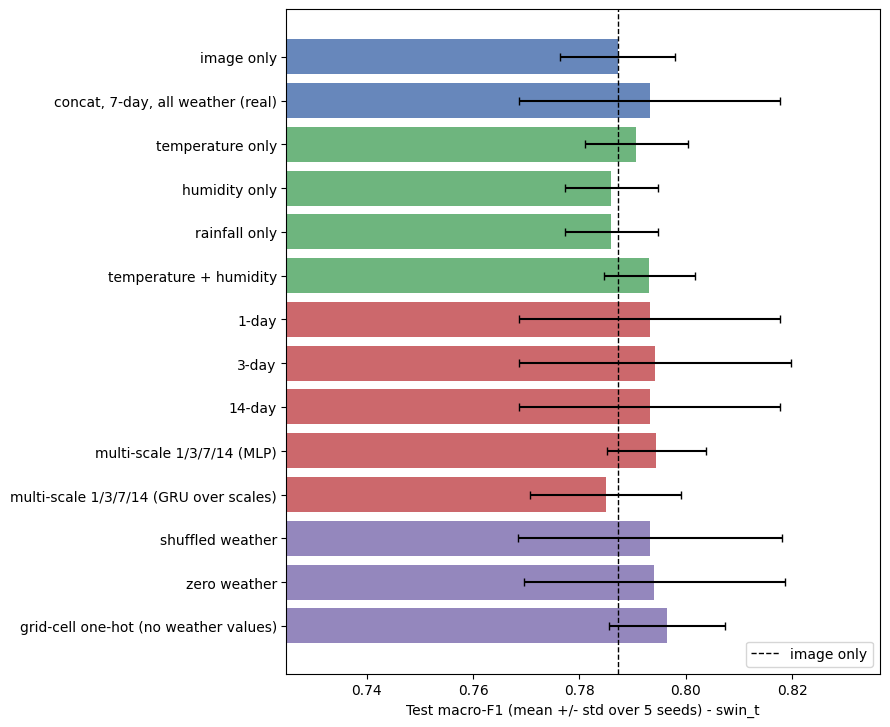

In [13]:
import matplotlib
import matplotlib.pyplot as plt

sum_all = summarize(res_df)
ref_rows = sum_all[sum_all["label"].isin([LABEL_IMG, LABEL_REAL])].copy()
ref_rows["group"] = "reference"
ref_rows["variant"] = ["image only", f"{BEST_FUSION}, 7-day, all weather (real)"] if ref_rows["label"].iloc[0] == LABEL_IMG \
    else [f"{BEST_FUSION}, 7-day, all weather (real)", "image only"]
ablation = pd.concat([ref_rows, sum_all[sum_all["stage"] == "B"]], ignore_index=True)
order = {"reference": 0, "feature": 1, "window": 2, "control": 3}
ablation = ablation.sort_values(by="group", key=lambda s: s.map(order), kind="stable").reset_index(drop=True)
display(ablation[["group", "variant", "val_f1", "test_acc", "test_f1", "test_f1_std"]].round(4))

fig, ax = plt.subplots(figsize=(9, 0.42 * len(ablation) + 1.5))
colors = {"reference": "#4c72b0", "feature": "#55a868", "window": "#c44e52", "control": "#8172b2"}
ypos = np.arange(len(ablation))[::-1]
ax.barh(ypos, ablation["test_f1"], xerr=ablation["test_f1_std"].fillna(0),
        color=[colors[g] for g in ablation["group"]], alpha=0.85, capsize=3)
ax.set_yticks(ypos)
ax.set_yticklabels(ablation["variant"])
img_f1 = float(sum_all.loc[sum_all["label"] == LABEL_IMG, "test_f1"].iloc[0])
ax.axvline(img_f1, color="k", ls="--", lw=1, label="image only")
ax.set_xlim(max(0, ablation["test_f1"].min() - 0.06), min(1, ablation["test_f1"].max() + 0.04))
ax.set_xlabel(f"Test macro-F1 (mean +/- std over {len(SEEDS)} seeds) - {BEST_BACKBONE}")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "phase4_ablation.png", dpi=200)
plt.show()

## 11. Paired group-bootstrap on the test set

Test images are resampled **by `split_group`** (duplicates and vineyards stay together), and the mean macro-F1 difference over seeds is recomputed on each resample. A 95% interval that includes 0 means the difference is not distinguishable from noise on this test set.

In [14]:
y_test = y_all[IDX["test"]]
groups_test = all_df["split_group"].values[IDX["test"]]
_, inv = np.unique(groups_test, return_inverse=True)
MEMBERS = [np.where(inv == g)[0] for g in range(inv.max() + 1)]


def boot_compare(label_a, label_b, B=BOOTSTRAP_B, seed=123, seeds=None):
    seeds = SEEDS if seeds is None else seeds
    pa = [PREDS[(label_a, s)] for s in seeds]
    pb = [PREDS[(label_b, s)] for s in seeds]

    def mean_diff(idx):
        return np.mean([fast_metrics(y_test[idx], a[idx], K)[0]["f1"] - fast_metrics(y_test[idx], b[idx], K)[0]["f1"]
                        for a, b in zip(pa, pb)])

    rng = np.random.default_rng(seed)
    full = np.arange(len(y_test))
    obs = mean_diff(full)
    diffs = np.empty(B)
    for i in range(B):
        pick = rng.integers(0, len(MEMBERS), len(MEMBERS))
        diffs[i] = mean_diff(np.concatenate([MEMBERS[k] for k in pick]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return {"observed_diff_f1": obs, "ci95_low": lo, "ci95_high": hi,
            "share_boot_diff_le_0": float((diffs <= 0).mean()),
            "ci_excludes_zero": bool(lo > 0 or hi < 0)}


comparisons = []
for fu in FUSIONS:
    if fu == "image_only":
        continue
    lab = make_label("A", BEST_BACKBONE, fu, DEFAULT_WEATHER, None)
    comparisons.append(("fusion vs image-only", f"{fu} (real weather)", "image only", lab, LABEL_IMG))

for ctrl_variant, ctrl in [("shuffled weather", "shuffled"), ("zero weather", "zeros"),
                           ("grid-cell one-hot", "grid_onehot")]:
    lab_ctrl = make_label("B", BEST_BACKBONE, BEST_FUSION, DEFAULT_WEATHER, ctrl)
    comparisons.append(("real vs control", f"{BEST_FUSION} (real weather)", ctrl_variant, LABEL_REAL, lab_ctrl))

rows = []
for kind, name_a, name_b, la, lb in comparisons:
    r = boot_compare(la, lb)
    rows.append({"comparison": kind, "A": name_a, "B": name_b, **r})
boot_df = pd.DataFrame(rows)
display(boot_df.round(4))

,comparison,A,B,observed_diff_f1,ci95_low,ci95_high,share_boot_diff_le_0,ci_excludes_zero
0,fusion vs image-only,concat (real weather),image only,0.0060,-0.0109,0.0238,0.231,False
1,fusion vs image-only,late (real weather),image only,0.0039,-0.0078,0.0161,0.287,False
2,fusion vs image-only,gated (real weather),image only,0.0067,-0.0062,0.0204,0.168,False
3,fusion vs image-only,film (real weather),image only,0.0058,-0.0066,0.0209,0.195,False
4,real vs control,concat (real weather),shuffled weather,-0.0000,-0.0012,0.0011,0.542,False
5,real vs control,concat (real weather),zero weather,-0.0008,-0.0024,0.0006,0.902,False
6,real vs control,concat (real weather),grid-cell one-hot,-0.0033,-0.0150,0.0102,0.730,False


## 12. Class-wise analysis: which diseases change with weather?

In [15]:
f1_cols = [f"f1_{c}" for c in class_names]
cw_img = res_df[res_df["label"] == LABEL_IMG][f1_cols]
cw_real = res_df[res_df["label"] == LABEL_REAL][f1_cols]
classwise = pd.DataFrame({
    "class": class_names,
    "f1_image_only": cw_img.mean().values,
    "f1_image_only_std": cw_img.std().values,
    f"f1_{BEST_FUSION}": cw_real.mean().values,
    f"f1_{BEST_FUSION}_std": cw_real.std().values,
})
classwise["delta_f1"] = classwise[f"f1_{BEST_FUSION}"] - classwise["f1_image_only"]
display(classwise.round(4))

,class,f1_image_only,f1_image_only_std,f1_concat,f1_concat_std,delta_f1
0,Black Rot,0.8910,0.0182,0.8778,0.0289,-0.0132
1,Esca,0.7580,0.0247,0.7714,0.0145,0.0134
2,Healthy,0.9806,0.0102,0.9913,0.0121,0.0107
3,Leaf Blight,0.5191,0.0437,0.5324,0.0729,0.0133


## 13. Part C: final end-to-end models (with checkpoints)

The validation-selected backbone + fusion head and the image-only head are trained end to end with image augmentation. The frozen backbone is kept in `eval()` mode (no BatchNorm updates or stochastic-depth noise). Checkpoints store the head, input standardisation, weather normalisation and config, so Phase 5 can rebuild the model and run Grad-CAM. Test-time weather zeroing/shuffling is reported as a diagnostic (it shows whether the trained model *uses* weather; the retrained controls above show whether weather *helps*).

In [16]:
FINAL_SPEC = DEFAULT_WEATHER if FINAL_SPEC is None else FINAL_SPEC
CKPT_DIR = OUTPUT_DIR / "checkpoints"
CKPT_DIR.mkdir(exist_ok=True)
amp_on = device.type == "cuda"

train_tf = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(8),
    transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.08),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class E2EDataset(Dataset):
    def __init__(self, rows, W, transform):
        self.rows, self.W, self.transform = np.asarray(rows), W, transform
        self.paths = all_df["image_path"].astype(str).values

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        r = int(self.rows[i])
        with Image.open(IMAGE_ROOT / self.paths[r]) as im:
            img = self.transform(im.convert("RGB"))
        return img, torch.from_numpy(self.W[r]), torch.tensor(int(y_all[r]))


def make_loader(rows, W, train):
    return DataLoader(E2EDataset(rows, W, train_tf if train else eval_tf), batch_size=FINAL_BATCH_SIZE,
                      shuffle=train, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))


def last_stage_modules(name, bb):
    if name == "convnext_tiny":
        return [bb.features[-1], bb.classifier[0]]
    if name == "swin_t":
        return [bb.features[-1], bb.norm]
    if name == "mobilenet_v2":
        return [bb.features[-1]]
    if name == "dinov2_s":
        return [bb.blocks[-1], bb.norm]
    raise ValueError(name)


class EndToEnd(nn.Module):
    def __init__(self, backbone_name, fusion, w_shape, encoder, finetune, stats=None):
        super().__init__()
        self.backbone_name, self.finetune = backbone_name, finetune
        self.backbone = build_backbone(backbone_name)
        for p in self.backbone.parameters():
            p.requires_grad = False
        self.ft_modules = []
        if finetune:
            self.ft_modules = last_stage_modules(backbone_name, self.backbone)
            for m in self.ft_modules:
                for p in m.parameters():
                    p.requires_grad = True
        mu, sd = EMB_STATS[backbone_name] if stats is None else stats
        self.register_buffer("mu", torch.tensor(np.asarray(mu), dtype=torch.float32))
        self.register_buffer("sd", torch.tensor(np.asarray(sd), dtype=torch.float32))
        self.head = FusionHead(self.mu.shape[0], K, fusion, w_shape, encoder)

    def train(self, mode=True):
        super().train(mode)
        self.backbone.eval()                 # frozen parts stay in eval mode
        if mode:
            for m in self.ft_modules:
                m.train()
        return self

    def forward(self, x, w):
        if self.finetune:
            f = self.backbone(x)
        else:
            with torch.no_grad():
                f = self.backbone(x)
        f = (f.float() - self.mu) / self.sd
        return self.head(f, None if self.head.fusion == "image_only" else w)


@torch.no_grad()
def eval_e2e(model, loader):
    model.eval()
    out = []
    for x, w, _ in loader:
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_on):
            logits = model(x.to(device, non_blocking=True), w.to(device))
        out.append(logits.argmax(1).cpu().numpy())
    return np.concatenate(out)


def ckpt_state(model):
    sd = model.state_dict()
    keep = (lambda k: True) if model.finetune else (lambda k: not k.startswith("backbone."))
    return {k: v.detach().cpu().clone() for k, v in sd.items() if keep(k)}


def load_state_checked(model, state, finetune):
    missing, unexpected = model.load_state_dict(state, strict=False)
    assert not unexpected, unexpected
    assert finetune or all(k.startswith("backbone.") for k in missing), missing


def train_final(backbone, fusion, spec, seed):
    seed_everything(seed)
    use_w = fusion != "image_only"
    W = make_weather(spec, None, seed) if use_w else np.zeros((len(all_df), 1, 1), np.float32)
    w_shape = tuple(W.shape[1:]) if use_w else None
    encoder = (spec or {}).get("encoder", "mlp")
    model = EndToEnd(backbone, fusion, w_shape, encoder, FINETUNE_LAST_STAGE).to(device)
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=FINAL_LR, weight_decay=WEIGHT_DECAY)
    scaler = torch.amp.GradScaler("cuda", enabled=amp_on)
    crit = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS)
    tr_loader, va_loader = make_loader(IDX["train"], W, True), make_loader(IDX["val"], W, False)
    y_val, y_test = y_all[IDX["val"]], y_all[IDX["test"]]

    best_f1, best_state, best_epoch, bad = -1.0, None, 0, 0
    t0 = time.time()
    for epoch in range(1, FINAL_EPOCHS + 1):
        model.train()
        for x, w, y in tr_loader:
            x, w, y = x.to(device, non_blocking=True), w.to(device), y.to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_on):
                loss = crit(model(x, w), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
        val_f1 = fast_metrics(y_val, eval_e2e(model, va_loader), K)[0]["f1"]
        print(f"  {fusion:<10} seed {seed} epoch {epoch:02d}/{FINAL_EPOCHS} val_f1={val_f1:.4f} ({(time.time() - t0) / 60:.1f} min)")
        if val_f1 > best_f1:
            best_f1, best_epoch, bad = val_f1, epoch, 0
            best_state = ckpt_state(model)
        else:
            bad += 1
            if bad >= 3:
                break

    load_state_checked(model, best_state, FINETUNE_LAST_STAGE)
    val_pred = eval_e2e(model, va_loader)
    te_loader = make_loader(IDX["test"], W, False)
    test_pred = eval_e2e(model, te_loader)
    val_m, _, _ = fast_metrics(y_val, val_pred, K)
    test_m, f1_cls, _ = fast_metrics(y_test, test_pred, K)
    row = {"seed": seed, "best_epoch": best_epoch, "val_acc": val_m["acc"], "val_f1": val_m["f1"],
           "test_acc": test_m["acc"], "test_precision": test_m["precision"], "test_recall": test_m["recall"],
           "test_f1": test_m["f1"]}
    for i, c in enumerate(class_names):
        row[f"f1_{c}"] = float(f1_cls[i])

    if use_w:   # test-time diagnostics on the trained model
        te = IDX["test"]
        rng = np.random.RandomState(2000 + seed)
        W_zero, W_shuf = W.copy(), W.copy()
        W_zero[te] = 0.0
        W_shuf[te] = W[rng.permutation(te)]
        row["test_f1_zero_weather"] = fast_metrics(y_test, eval_e2e(model, make_loader(te, W_zero, False)), K)[0]["f1"]
        row["test_f1_shuffled_weather"] = fast_metrics(y_test, eval_e2e(model, make_loader(te, W_shuf, False)), K)[0]["f1"]

    raw = raw_weather(spec["windows"], spec["features"]) if use_w else None
    ckpt = {"state": best_state, "backbone": backbone, "fusion": fusion, "spec": spec if use_w else None,
            "w_shape": w_shape, "encoder": encoder, "finetune": FINETUNE_LAST_STAGE, "class_names": class_names,
            "image_size": IMAGE_SIZE, "imagenet_mean": IMAGENET_MEAN, "imagenet_std": IMAGENET_STD,
            "seed": seed, "best_epoch": best_epoch,
            "weather_mean": None if raw is None else raw[IDX["train"]].mean(0).tolist(),
            "weather_std": None if raw is None else raw[IDX["train"]].std(0).tolist()}
    path = CKPT_DIR / f"final_{backbone}_{fusion}_seed{seed}.pt"
    torch.save(ckpt, path)
    row["checkpoint"] = str(path)
    del model, opt
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return row, test_pred


def load_final_model(path):
    # Rebuild a saved end-to-end model (used for the reload check here and for Phase 5 Grad-CAM).
    ck = torch.load(path, map_location="cpu", weights_only=False)
    seed_everything(ck["seed"])   # only matters when PRETRAINED=False (random backbone); pretrained weights are deterministic
    stats = (ck["state"]["mu"].numpy(), ck["state"]["sd"].numpy())
    model = EndToEnd(ck["backbone"], ck["fusion"], ck["w_shape"], ck["encoder"], ck["finetune"], stats=stats)
    load_state_checked(model, ck["state"], ck["finetune"])
    return model.to(device).eval(), ck


def final_label(fu):
    return f"FINAL|{BEST_BACKBONE}|{fu}"

In [17]:
if RUN_FINAL:
    print("Final backbone:", BEST_BACKBONE, "| fusion:", BEST_FUSION, "| seeds:", FINAL_SEEDS,
          "| fine-tune last stage:", FINETUNE_LAST_STAGE)
    for fu in ["image_only", BEST_FUSION]:
        for s in FINAL_SEEDS:
            t0 = time.time()
            row, pred = train_final(BEST_BACKBONE, fu, None if fu == "image_only" else FINAL_SPEC, s)
            row.update({"label": final_label(fu), "stage": "FINAL", "backbone": BEST_BACKBONE, "fusion": fu,
                        "group": "final end-to-end", "variant": f"{BEST_BACKBONE} / {fu} (end-to-end)",
                        "weather": spec_name(None if fu == "image_only" else FINAL_SPEC), "control": None})
            RESULTS.append(row)
            PREDS[(final_label(fu), s)] = pred
            print(f"{fu:<10} seed {s}: test_f1 {row['test_f1']:.4f} | val_f1 {row['val_f1']:.4f} | {(time.time() - t0) / 60:.1f} min")

Final backbone: swin_t | fusion: concat | seeds: [0, 1, 2] | fine-tune last stage: False
  image_only seed 0 epoch 01/8 val_f1=0.8125 (0.6 min)
  image_only seed 0 epoch 02/8 val_f1=0.8092 (1.3 min)
  image_only seed 0 epoch 03/8 val_f1=0.8265 (1.9 min)
  image_only seed 0 epoch 04/8 val_f1=0.8202 (2.5 min)
  image_only seed 0 epoch 05/8 val_f1=0.8011 (3.1 min)
  image_only seed 0 epoch 06/8 val_f1=0.7989 (3.8 min)
image_only seed 0: test_f1 0.8063 | val_f1 0.8265 | 4.0 min
  image_only seed 1 epoch 01/8 val_f1=0.8071 (0.6 min)
  image_only seed 1 epoch 02/8 val_f1=0.8116 (1.3 min)
  image_only seed 1 epoch 03/8 val_f1=0.8086 (1.9 min)
  image_only seed 1 epoch 04/8 val_f1=0.8109 (2.5 min)
  image_only seed 1 epoch 05/8 val_f1=0.8075 (3.2 min)
image_only seed 1: test_f1 0.7823 | val_f1 0.8116 | 3.4 min
  image_only seed 2 epoch 01/8 val_f1=0.7968 (0.6 min)
  image_only seed 2 epoch 02/8 val_f1=0.7969 (1.3 min)
  image_only seed 2 epoch 03/8 val_f1=0.8000 (1.9 min)
  image_only seed 2 e

### Final results, paired bootstrap, weather diagnostics, checkpoint reload check

,fusion,val_f1,test_acc,test_acc_std,test_f1,test_f1_std,n_seeds
0,image_only,0.8180,0.8405,0.0062,0.7928,0.0123,3
1,concat,0.8272,0.8527,0.0049,0.8041,0.0098,3


,comparison,A,B,observed_diff_f1,ci95_low,ci95_high,share_boot_diff_le_0,ci_excludes_zero
0,final end-to-end: fusion vs image-only,concat (real weather),image only,0.0114,-0.0061,0.0305,0.113,False


Test-time weather diagnostics (trained fusion model; a drop means the model uses weather):


,seed,test_f1,test_f1_zero_weather,test_f1_shuffled_weather
113,0,0.7932,0.7918,0.7932
114,1,0.8120,0.8106,0.8106
115,2,0.8071,0.8044,0.8042


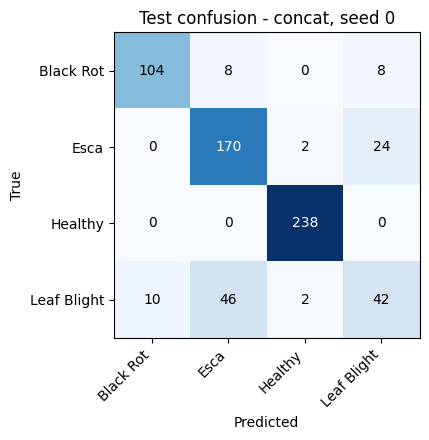

Checkpoint reload agreement on 64 test images: 1.000  (final_swin_t_concat_seed0.pt)


In [18]:
if RUN_FINAL:
    res_df = pd.DataFrame(RESULTS)
    fin = res_df[res_df["stage"] == "FINAL"]
    final_summary = fin.groupby("fusion", sort=False).agg(
        val_f1=("val_f1", "mean"), test_acc=("test_acc", "mean"), test_acc_std=("test_acc", "std"),
        test_f1=("test_f1", "mean"), test_f1_std=("test_f1", "std"), n_seeds=("seed", "nunique")).reset_index()
    display(final_summary.round(4))

    final_boot_df = pd.DataFrame([{
        "comparison": "final end-to-end: fusion vs image-only", "A": f"{BEST_FUSION} (real weather)", "B": "image only",
        **boot_compare(final_label(BEST_FUSION), final_label("image_only"), seeds=FINAL_SEEDS)}])
    display(final_boot_df.round(4))

    diag = fin[fin["fusion"] == BEST_FUSION][["seed", "test_f1", "test_f1_zero_weather", "test_f1_shuffled_weather"]]
    print("Test-time weather diagnostics (trained fusion model; a drop means the model uses weather):")
    display(diag.round(4))

    # confusion matrix of the validation-selected fusion model (first seed), not chosen on test
    cm = fast_metrics(y_test, PREDS[(final_label(BEST_FUSION), FINAL_SEEDS[0])], K)[2]
    pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(OUTPUT_DIR / "phase4_final_confusion_matrix.csv")
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(K)); ax.set_yticks(range(K))
    ax.set_xticklabels(class_names, rotation=45, ha="right"); ax.set_yticklabels(class_names)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(f"Test confusion - {BEST_FUSION}, seed {FINAL_SEEDS[0]}")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "phase4_final_confusion_matrix.png", dpi=200)
    plt.show()

    # reload check: a saved checkpoint must reproduce its predictions
    ck_path = CKPT_DIR / f"final_{BEST_BACKBONE}_{BEST_FUSION}_seed{FINAL_SEEDS[0]}.pt"
    m, ck = load_final_model(ck_path)
    W_chk = make_weather(ck["spec"], None, ck["seed"])
    n_chk = min(64, len(IDX["test"]))
    p_chk = eval_e2e(m, make_loader(IDX["test"][:n_chk], W_chk, False))
    agree = float((p_chk == PREDS[(final_label(BEST_FUSION), FINAL_SEEDS[0])][:n_chk]).mean())
    print(f"Checkpoint reload agreement on {n_chk} test images: {agree:.3f}  ({ck_path.name})")
    del m
else:
    print("RUN_FINAL is False: skipping Part C.")

## 14. Save everything for Phase 5

In [19]:
res_df = pd.DataFrame(RESULTS)
res_df.to_csv(OUTPUT_DIR / "phase4_all_runs.csv", index=False)
sum_all = summarize(res_df)
sum_all.to_csv(OUTPUT_DIR / "phase4_summary.csv", index=False)
sumA.to_csv(OUTPUT_DIR / "phase4_stageA_backbone_fusion.csv", index=False)
ablation.to_csv(OUTPUT_DIR / "phase4_ablation_table.csv", index=False)
boot_df.to_csv(OUTPUT_DIR / "phase4_bootstrap_comparisons.csv", index=False)
if RUN_FINAL:
    final_boot_df.to_csv(OUTPUT_DIR / "phase4_final_bootstrap.csv", index=False)
    final_summary.to_csv(OUTPUT_DIR / "phase4_final_end2end_summary.csv", index=False)
classwise.to_csv(OUTPUT_DIR / "phase4_classwise.csv", index=False)

safe = lambda s: s.replace("|", "__").replace("=", "-").replace(";", "_").replace("/", "-").replace(" ", "")
np.savez_compressed(OUTPUT_DIR / "phase4_test_predictions.npz",
                    y_test=y_test, groups_test=groups_test,
                    **{f"{safe(l)}__seed{s}": p for (l, s), p in PREDS.items()})

best_cfg = {
    "backbone": BEST_BACKBONE, "fusion": BEST_FUSION, "weather": DEFAULT_WEATHER,
    "seeds": SEEDS, "class_names": class_names, "final_seeds": FINAL_SEEDS,
    "finetune_last_stage": FINETUNE_LAST_STAGE, "checkpoint_dir": str(CKPT_DIR),
    "head": dict(hidden=HEAD_HIDDEN, weather_dim=WEATHER_DIM, dropout=DROPOUT, lr=LR,
                 weight_decay=WEIGHT_DECAY, epochs=EPOCHS, patience=PATIENCE),
    "selection_rule": "validation macro-F1 (image-only head picks backbone; weather heads pick fusion)",
}
(OUTPUT_DIR / "phase4_best_config.json").write_text(json.dumps(best_cfg, indent=2))
print("Saved to:", OUTPUT_DIR)
print(sorted(p.name for p in OUTPUT_DIR.iterdir()))

Saved to: /content/drive/MyDrive/DATASET/docs/phase4_outputs_claude
['checkpoints', 'embeddings', 'grid_vs_class_counts.csv', 'phase4_ablation.png', 'phase4_ablation_table.csv', 'phase4_all_runs.csv', 'phase4_best_config.json', 'phase4_bootstrap_comparisons.csv', 'phase4_classwise.csv', 'phase4_final_bootstrap.csv', 'phase4_final_confusion_matrix.csv', 'phase4_final_confusion_matrix.png', 'phase4_final_end2end_summary.csv', 'phase4_stageA_backbone_fusion.csv', 'phase4_summary.csv', 'phase4_test_predictions.npz', 'weather_audit.csv']


## 15. How to read these results (decision rules)

Use the tables above to decide what the paper can honestly claim.

| Observation | What it means | What you can write |
|---|---|---|
| Real-weather fusion CI vs image-only **includes 0** | No measurable benefit on this test set | "Weather did not improve classification in this dataset" is a valid, publishable negative result |
| Real weather **beats shuffled/zero** but **matches grid-cell one-hot** | The gain is a location prior, not weather physiology | Report it as location context; do not claim weather-disease dynamics |
| Real weather **beats** shuffled, zeros **and** grid-cell one-hot with CI excluding 0 | Evidence that the weather values carry signal | Still caveat: one capture date, few grid cells |
| Feature/window ablations differ by less than the seed std | The ablation ranking is noise | Do not rank variables or windows from it |
| Weather-only (Phase 3) near majority-class accuracy | No label leakage through weather | Good for the leakage-control claim |

Because every image was captured on one date at a handful of locations, the **window ablation cannot show true temporal effects** (the 1/3/7/14-day windows vary only through the grid cell and the days before a single date). Collecting images across multiple dates and seasons is the fix, and a strong "future work" or a data-collection contribution.

### Phase 5 plan (next notebook)

1. Load a checkpoint from `phase4_outputs/checkpoints/` with `load_final_model` (copy `build_backbone`, `FusionHead`, `EndToEnd` into the new notebook) for **Grad-CAM / attention maps** on the image branch and **permutation importance** for the weather branch.
2. Re-run the selected config on additional **group-shuffled splits** to capture split variance, not only seed variance.
3. Optional: set `FINETUNE_LAST_STAGE = True` and compare against the frozen result.
4. Replace the fake numbers in the paper with the tables from `phase4_*.csv`, and state the one-date / few-grid-cell limitation explicitly.